# NyahMuk Model 2: water and wet-surface detector (v2: longer training)
Train YOLOv8s on the cleaned Stagnant Water and Wet Surface data, then test it on the held-out test split.
**Before you start:** Runtime > Change runtime type > **T4 GPU**. Run the cells top to bottom.

## Step 0. Check the GPU and install YOLO

In [1]:
!nvidia-smi
%pip -q install ultralytics

Sun Oct 18 03:38:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 1. Mount Drive and set the configuration

In [9]:
import os, re, ast, json, random, shutil, zipfile
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not running in Colab

# ---- paths ----
ZIP_CLEAN = Path('/content/drive/MyDrive/NyahMuk/clean_output/nyahmuk_clean_v2.zip')   # made by the fix cell
CLEAN = Path('/content/clean')                                                          # where it is unzipped
RUNS  = Path('/content/drive/MyDrive/NyahMuk/runs')                                     # results are saved on Drive
WATER_ONLY = True   # False = same 2 classes as v1 (only longer training).  True = keep only 'water'; 'wet surface' becomes background
RUN_NAME = 'model2_water_only_v2' if WATER_ONLY else 'model2_stagnant_water_v2'
DS = 'stagnant_water_wateronly' if WATER_ONLY else 'stagnant_water'

# ---- training settings ----
MODEL = 'yolov8s.pt'   # small pretrained YOLOv8 (downloaded automatically)
EPOCHS = 50
IMGSZ = 320   # the images are only 256x256, so 320 is plenty
BATCH = 32
PATIENCE = 15          # stop early if validation does not improve for 30 epochs
SEED = 42
ALLOW_CPU = False

HAS_GPU = torch.cuda.is_available()
DEVICE = 0 if HAS_GPU else 'cpu'
print('GPU:', torch.cuda.get_device_name(0) if HAS_GPU else 'NONE')
assert HAS_GPU or ALLOW_CPU, 'No GPU found. Runtime > Change runtime type > T4 GPU, then run again.'
RUNS.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4


## Step 2. Unzip the clean data and write the dataset file

In [10]:
if not (CLEAN / 'stagnant_water').exists():
    assert ZIP_CLEAN.exists(), f'Not found: {ZIP_CLEAN}. Run the v2 fix cell first, or point ZIP_CLEAN at the v1 zip.'
    zipfile.ZipFile(ZIP_CLEAN).extractall(CLEAN)

src = (CLEAN / 'stagnant_water' / 'data.yaml').read_text()
NAMES = ast.literal_eval(re.search(r'names:\s*(\[.*?\])', src).group(1))

if WATER_ONLY:
    # copy the dataset, keeping only class 0 (water). Images with only wet surface get an empty label file = background.
    NAMES = [NAMES[0]]
    for s_ in ['train', 'valid', 'test']:
        (CLEAN / DS / s_ / 'images').mkdir(parents=True, exist_ok=True)
        (CLEAN / DS / s_ / 'labels').mkdir(parents=True, exist_ok=True)
        for img in (CLEAN / 'stagnant_water' / s_ / 'images').glob('*'):
            shutil.copy(img, CLEAN / DS / s_ / 'images' / img.name)
            lines = (CLEAN / 'stagnant_water' / s_ / 'labels' / (img.stem + '.txt')).read_text().splitlines()
            keep = [l for l in lines if l.strip() and int(float(l.split()[0])) == 0]
            (CLEAN / DS / s_ / 'labels' / (img.stem + '.txt')).write_text('\n'.join(keep) + ('\n' if keep else ''))

YAML = Path('/content/model2_data.yaml')
YAML.write_text(f"path: {CLEAN / DS}\ntrain: train/images\nval: valid/images\ntest: test/images\nnc: {len(NAMES)}\nnames: {NAMES}\n")
print(YAML.read_text())

path: /content/clean/stagnant_water_wateronly
train: train/images
val: valid/images
test: test/images
nc: 1
names: ['water']



## Step 3. Sanity check the data before training

In [11]:
rows, per_split = [], {}
for s in ['train', 'valid', 'test']:
    imgs = sorted((CLEAN / DS / s / 'images').glob('*'))
    lbls = sorted((CLEAN / DS / s / 'labels').glob('*.txt'))
    cnt = np.zeros(len(NAMES), dtype=int)
    for l in lbls:
        for ln in l.read_text().split('\n'):
            if ln.strip(): cnt[int(float(ln.split()[0]))] += 1
    per_split[s] = cnt
    rows.append(dict(split=s, images=len(imgs), label_files=len(lbls), boxes=int(cnt.sum())))
    assert len(imgs) == len(lbls), f'{s}: images and labels do not match'
display(pd.DataFrame(rows))
display(pd.DataFrame(per_split, index=NAMES).T)

,split,images,label_files,boxes
0,train,1445,1445,14306
1,valid,182,182,1746
2,test,180,180,1771


,water
train,14306
valid,1746
test,1771


## Step 4. Train
The first run downloads the pretrained weights. Each epoch prints precision, recall and mAP on the **valid** split. Results and weights are saved to Drive after every epoch, so a disconnect does not lose them.

In [12]:
from ultralytics import YOLO
model = YOLO(MODEL)
results = model.train(
    data=str(YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
    seed=SEED, device=DEVICE, project=str(RUNS), name=RUN_NAME, workers=2, plots=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST = RUN_DIR / 'weights' / 'best.pt'
print('Run folder  :', RUN_DIR)
print('Best weights:', BEST)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/model2_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=model2_water_only_v2, nbs=64, nms=None, opset=None, optimize=Fa

**If Colab disconnects mid-training**, reconnect, run Steps 0 to 3, then run this cell instead of Step 4 (set the folder name to your run, it may end in a number):

In [ ]:
# from ultralytics import YOLO
# RUN_DIR = RUNS / 'model2_stagnant_water_v1'
# YOLO(RUN_DIR / 'weights' / 'last.pt').train(resume=True)

## Step 5. Evaluate on valid and test

In [13]:
best = YOLO(BEST)

def evaluate(split):
    m = best.val(data=str(YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                 project=str(RUNS), name=f'{RUN_NAME}_{split}', exist_ok=True, plots=True, verbose=False)
    per = []
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        per.append({'class': m.names[int(c)], 'precision': p, 'recall': r, 'mAP50': ap50, 'mAP50-95': ap})
    overall = {'class': 'ALL', 'precision': m.box.mp, 'recall': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map}
    return pd.DataFrame(per + [overall]).round(3), RUNS / f'{RUN_NAME}_{split}'

val_tbl,  val_dir  = evaluate('val')
test_tbl, test_dir = evaluate('test')
print('VALID split (used to pick the best epoch, so slightly optimistic):'); display(val_tbl)
print('TEST split (never used for training or picking, the honest score):'); display(test_tbl)
test_tbl.to_csv(RUNS / f'{RUN_NAME}_test_per_class.csv', index=False)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 492.4±86.3 MB/s, size: 15.8 KB)
val: Scanning /content/clean/stagnant_water_wateronly/valid/labels.cache... 182 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 182/182 58.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.2it/s 2.8s
                   all        182       1746      0.299      0.325      0.242     0.0675
Speed: 1.1ms preprocess, 3.2ms inference, 0.0ms loss, 5.5ms postprocess per image
Results saved to /content/drive/MyDrive/NyahMuk/runs/model2_water_only_v2_val
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0

,class,precision,recall,mAP50,mAP50-95
0,water,0.299,0.325,0.242,0.067
1,ALL,0.299,0.325,0.242,0.067


TEST split (never used for training or picking, the honest score):


,class,precision,recall,mAP50,mAP50-95
0,water,0.299,0.299,0.225,0.062
1,ALL,0.299,0.299,0.225,0.062


## Step 6. Look at the curves and the confusion matrix

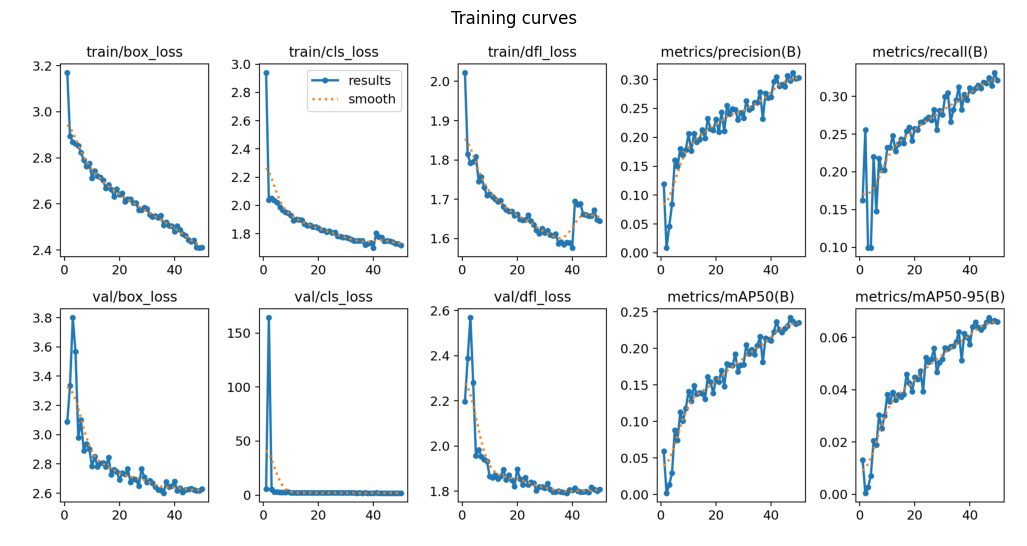

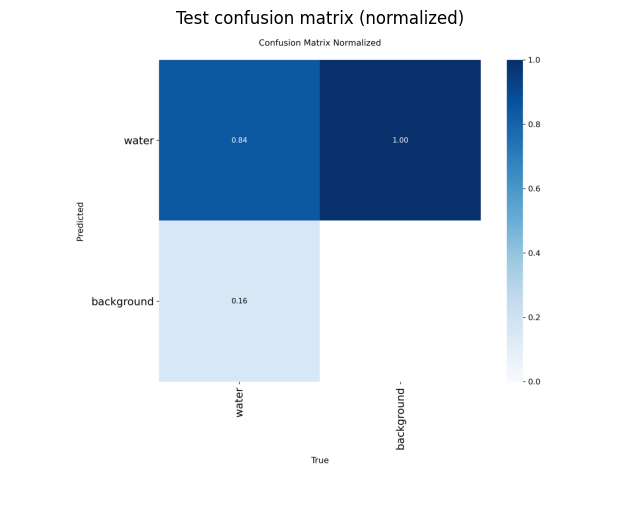

In [14]:
def show_img(path, title, size=(9, 6)):
    if Path(path).exists():
        plt.figure(figsize=size); plt.imshow(Image.open(path)); plt.axis('off'); plt.title(title); plt.show()
    else:
        print('missing:', path)

show_img(RUN_DIR / 'results.png', 'Training curves', (13, 7))
cm = next(iter(sorted(test_dir.glob('confusion_matrix*normalized*.png'))), None)
show_img(cm, 'Test confusion matrix (normalized)', (8, 7)) if cm else print('confusion matrix image not found in', test_dir)

## Step 7. Predictions on random test images

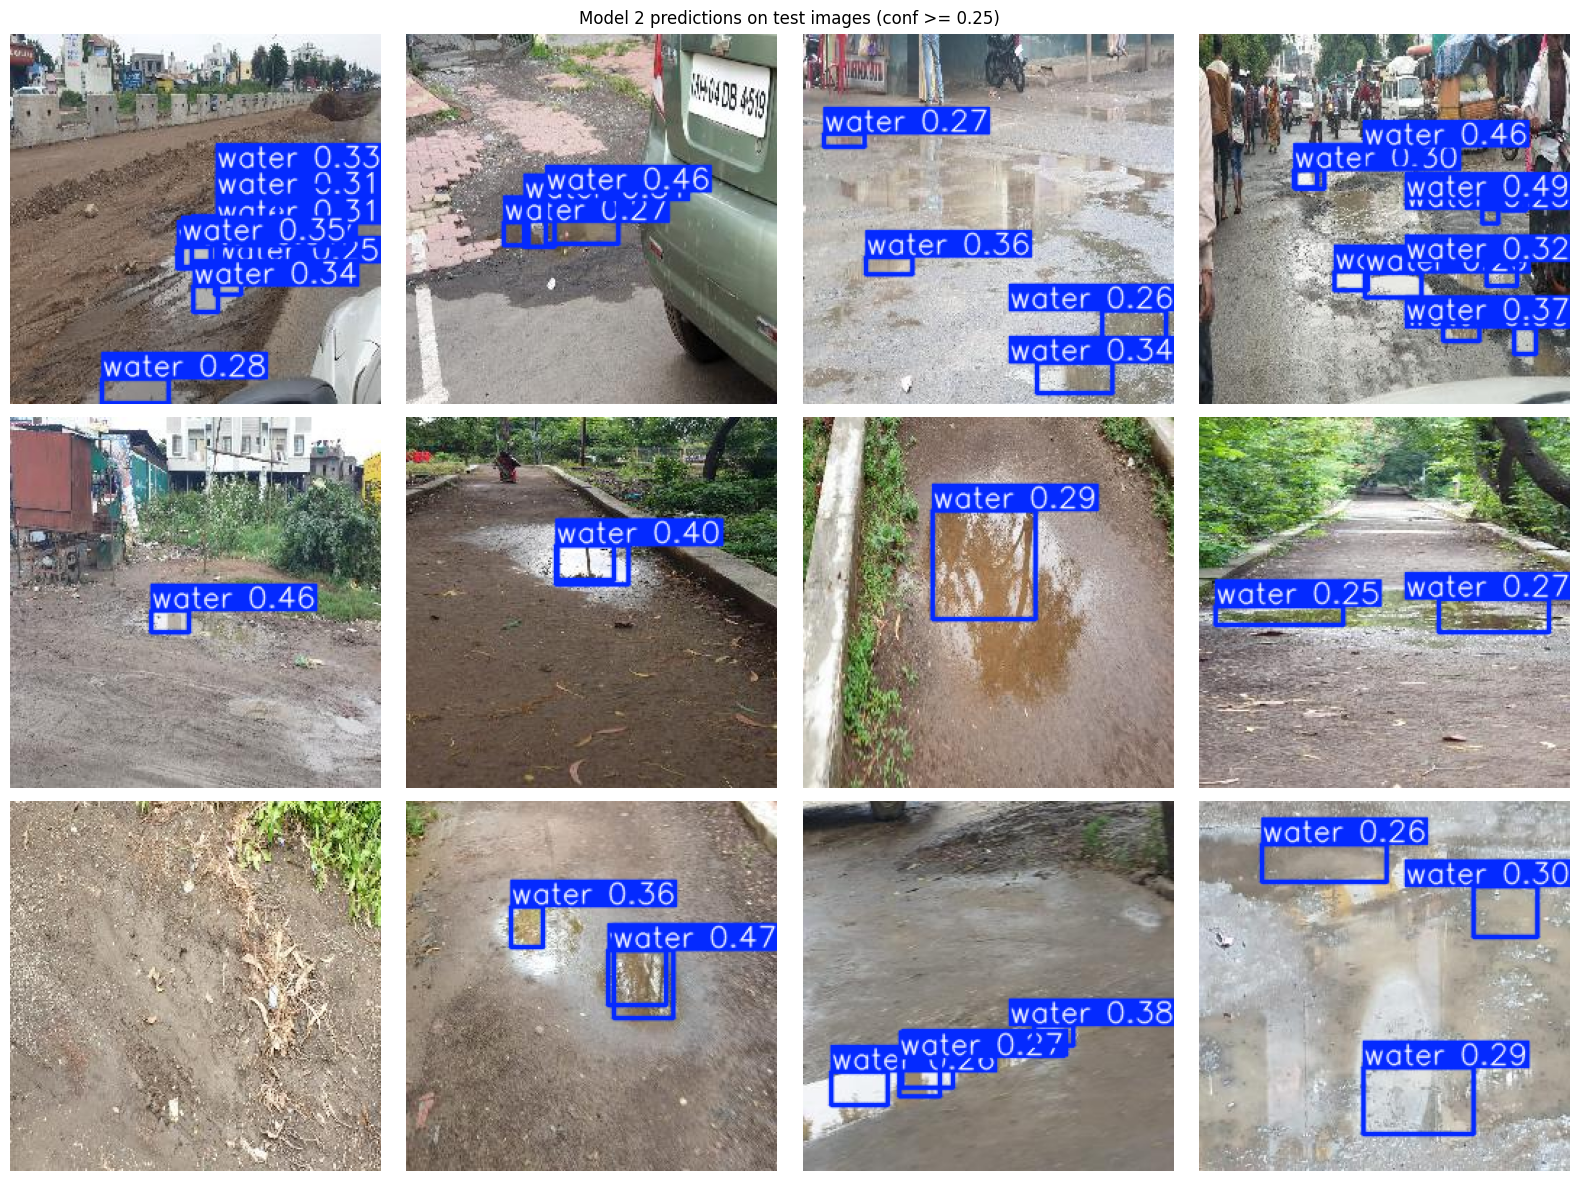

In [15]:
test_imgs = sorted((CLEAN / DS / 'test' / 'images').glob('*'))
sel = random.Random(1).sample(test_imgs, min(12, len(test_imgs)))
preds = best.predict([str(p) for p in sel], conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, r in zip(axes.flatten(), preds):
    ax.imshow(r.plot()[:, :, ::-1]); ax.axis('off')
plt.suptitle('Model 2 predictions on test images (conf >= 0.25)'); plt.tight_layout(); plt.show()

## Step 8. Save a summary

In [16]:
summary = dict(run=str(RUN_DIR), model=MODEL, epochs_requested=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
               classes=NAMES, test=test_tbl.set_index('class').to_dict('index'), valid=val_tbl.set_index('class').to_dict('index'))
(RUNS / f'{RUN_NAME}_summary.json').write_text(json.dumps(summary, indent=2))
print('Saved summary to', RUNS / f'{RUN_NAME}_summary.json')
print('Best weights   :', BEST)

Saved summary to /content/drive/MyDrive/NyahMuk/runs/model2_water_only_v2_summary.json
Best weights   : /content/drive/MyDrive/NyahMuk/runs/model2_water_only_v2/weights/best.pt


## How to read the results
- Compare with v1 (test mAP50 0.212, precision 0.299, recall 0.281). Did longer training help, and by how much?
- If you ran `WATER_ONLY = True`, the numbers are for the single class 'water' and are not directly comparable per class, but overall mAP50 and precision are.
- Water is hard to box (many small overlapping boxes), so even a good run will score far below Model 1. Judge it by the prediction pictures and by your own photos.
- Seeing water does NOT prove it is stagnant or has larvae. This model only provides visible-water evidence.